In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgba
from matplotlib.path import Path
from matplotlib.ticker import MultipleLocator
import matplotlib as mpl
import re
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple


mpl.rcParams["path.simplify"] = False

# =========================
# Helpers
# =========================
def to_num(s):
    return pd.to_numeric(s, errors="coerce")


def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    if re.match(r"^Reference\s+\d+$", lbl):
        return "Literature Report"
    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"
    if lbl.lower() == "this work":
        return "Ours"

    return lbl


def pareto_frontier_xy(pts: pd.DataFrame) -> pd.DataFrame:
    # X lower is better, Y higher is better
    s = pts.sort_values(["x", "y"], ascending=[True, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r["y"] > best_y:
            keep.append(True)
            best_y = r["y"]
        else:
            keep.append(False)
    return s.loc[keep].reset_index(drop=True)


def enclosure_polygon(front: pd.DataFrame, x_ref: float, y_ref: float):
    """
    Build the closed enclosure like your figure:
    left-bottom -> left-front-start -> along pareto front
    -> right edge -> bottom edge -> back to left-bottom
    """
    f = front.sort_values("x", ascending=True).reset_index(drop=True)
    x0, y0 = float(f.loc[0, "x"]), float(f.loc[0, "y"])
    y_last = float(f.loc[len(f) - 1, "y"])

    pts = (
        [(x0, y_ref), (x0, y0)]
        + list(map(tuple, f[["x", "y"]].iloc[1:].to_numpy()))
        + [(x_ref, y_last), (x_ref, y_ref)]
    )
    return pts


# =========================
# 1) Load source data
# =========================
from pathlib import Path as FsPath

# Literature/control points are kept in the original Figure 1 workbook.
# The "This work" points now come from the repo-level corrected 708-sample table.
excel_path = FsPath("../data/all_data_corrected.xlsx")
all_samples_path = FsPath("../../../all_samples_708_corrected.csv")

raw = pd.read_excel(excel_path, sheet_name="Sheet1")
raw.columns = raw.columns.map(lambda c: str(c).strip())

# first row repeats headers
lit_df = raw.iloc[1:].copy()

# =========================
# 2) Map each dataset to (x, y) columns
# =========================
# This work is intentionally excluded here and rebuilt from all_samples_708_corrected.csv.
datasets = [
    ("24", "Unnamed: 3"),
    ("26", "Unnamed: 5"),
    ("25", "Unnamed: 7"),
    ("27", "Unnamed: 9"),
    ("23", "Unnamed: 11"),
    ("20", "Unnamed: 13"),
    ("22", "Unnamed: 15"),
    ("Ni foam", "Unnamed: 17"),
    ("Pt sheet", "Unnamed: 19"),
    ("28", "Unnamed: 21"),
    ("29", "Unnamed: 23"),
    ("30", "Unnamed: 25"),
    ("31", "Unnamed: 27"),
    ("32", "Unnamed: 29")
]

rows = []
for x_col, y_col in datasets:
    if x_col not in lit_df.columns or y_col not in lit_df.columns:
        print(f"[WARN] Missing columns: {x_col} / {y_col}")
        continue

    x = to_num(lit_df[x_col])
    y = to_num(lit_df[y_col])
    tmp = pd.DataFrame({"label": x_col, "x": x, "y": y}).dropna()
    rows.append(tmp)

all_samples = pd.read_csv(all_samples_path)
ours = pd.DataFrame({
    "label": "This work",
    "x": -to_num(all_samples["Potential (V)"]) * 1000,
    "y": to_num(all_samples["separation_coefficient"]),
}).dropna()
ours["x"] = ours["x"].clip(upper=550)

rows.append(ours)

data = pd.concat(rows, ignore_index=True)
data = data[np.isfinite(data["x"]) & np.isfinite(data["y"])].copy()
data = data.reset_index(drop=True)
data["pid"] = data.index

# Rename numeric refs
data["label"] = data["label"].astype(str).str.strip()
data["label"] = data["label"].apply(lambda s: f"Reference {s}" if s.isdigit() else s)

# =========================
# 3) Split data
# =========================
is_this = data["label"].str.strip().str.lower().eq("this work")

pre = data[~is_this].copy()      # literature + Ni foam + Pt sheet
ours = data[is_this].copy()      # This work only

# Blue Pareto front: literature/control points
front_pre = pareto_frontier_xy(pre)

# Red Pareto front: This work only
front_ours = pareto_frontier_xy(ours)

pareto_ids = set(front_ours["pid"])

print(
    "Counts:",
    "pre points =", len(pre),
    "| ours points =", len(ours),
    "| front_pre =", len(front_pre),
    "| front_ours =", len(front_ours),
)

# =========================
# 4) Build enclosure polygons
# =========================
x_max = float(data["x"].max())
y_min = float(data["y"].min())

x_ref = x_max + 1e-6
y_ref = y_min - 1e-6

# Blue enclosure from literature front
poly_pre = enclosure_polygon(front_pre, 550, y_ref)

# Red enclosure from This work front, but closed to bottom/right like your image
poly_ours = enclosure_polygon(front_ours, x_ref, y_ref)

# =========================
# 5) Plot
# =========================
fig, ax = plt.subplots(figsize=(16, 8))

def label_sort_key(lbl: str):
    lbl = str(lbl)
    if lbl.startswith("Reference "):
        try:
            return (0, int(lbl.split()[-1]))
        except Exception:
            return (0, 10**9)
    if lbl == "Ni foam":
        return (1, 0)
    if lbl == "Pt sheet":
        return (1, 1)
    return (2, lbl)

other_labels = sorted(pre["label"].unique(), key=label_sort_key)

palette = [
    "#0072B2",
    "#E69F00",
    "#5510A0",
    "#D52B00",
    "#F0E442",
    "#D182AE",
    "#818CEC",
    "#6B3C03",
    "#19C7C7",
    "#2B3FB1",
    "#C2BD73",
    "#D86EAF",
    "#15DB99",
    "#7EC455",
]

markers = ["^"]

style = {}
for i, lbl in enumerate(other_labels):
    style[lbl] = dict(
        marker=markers[i % len(markers)],
        color=palette[i % len(palette)]
    )

c_pre = "blue"
c_post = "red"

# Enclosures
ax.add_patch(
    Polygon(
        poly_pre,
        closed=True,
        facecolor=to_rgba(c_pre, 0.02),
        edgecolor=to_rgba(c_pre, 1.0),
        linewidth=2.0,
        zorder=1
    )
)

ax.add_patch(
    Polygon(
        poly_ours,
        closed=True,
        facecolor=to_rgba(c_post, 0.04),
        edgecolor=to_rgba(c_post, 1.0),
        linewidth=2.5,
        zorder=1
    )
)

# Literature points
pre_plot = pre.copy()

for lbl in other_labels:
    sub = pre_plot[pre_plot["label"] == lbl]
    ax.scatter(
        sub["x"], sub["y"],
        s=150,
        alpha=0.85,
        label=legend_name(lbl),
        zorder=4,
        **style[lbl],
        edgecolors="black",
        linewidths=0.7,
    )

# This work points
thisw = data[is_this].copy()
thisw_nonpareto = thisw[~thisw["pid"].isin(pareto_ids)]

pre_path = Path(poly_pre)
inside_pre = pre_path.contains_points(thisw_nonpareto[["x", "y"]].to_numpy(), radius=1e-9)

ax.scatter(
    thisw_nonpareto.loc[inside_pre, "x"],
    thisw_nonpareto.loc[inside_pre, "y"],
    marker="o",
    s=80,
    color="gray",
    alpha=0.5,
    edgecolors="black",
    linewidths=0.7,
    label="Ours",
    zorder=3
)

ax.scatter(
    thisw_nonpareto.loc[~inside_pre, "x"],
    thisw_nonpareto.loc[~inside_pre, "y"],
    marker="X",
    s=80,
    color="#F3A0A0",
    alpha=0.9,
    edgecolors="black",
    linewidths=0.7,
    label="Ours",
    zorder=3
)

# Pareto front lines
ax.plot(front_pre["x"], front_pre["y"], color=c_pre, linewidth=2.5, zorder=2)
ax.plot(front_ours["x"], front_ours["y"], color=c_post, linewidth=2.5, zorder=2)

# Pareto stars for This work only
ax.scatter(
    front_ours["x"], front_ours["y"],
    marker="*",
    s=380,
    color="red",
    edgecolors="black",
    linewidths=0.7,
    zorder=10,
    label="Ours"
)

ax.set_ylabel(
    "Separation Coefficient (@ -50 mA/cm²)",
    fontname="Arial",
    fontweight="bold",
    fontsize=24
)
ax.set_xlabel(
    "Overpotential (@ -10 mA/cm², mV)",
    fontname="Arial",
    fontweight="bold",
    fontsize=24
)

ax.yaxis.set_major_locator(MultipleLocator(2))
ax.tick_params(axis="both", which="both", labelsize=24)

for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontname("Arial")
    t.set_fontweight("bold")

ax.set_xlim(-10, x_ref + 10)
ax.set_ylim(2, 21)

old_leg = ax.get_legend()
if old_leg is not None:
    old_leg.remove()

h_lit = Line2D(
    [0], [0],
    marker="^",
    linestyle="None",
    markersize=11,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=0.9,
    label="Literature Report"
)

h_inside = Line2D(
    [0], [0],
    marker="o",
    linestyle="None",
    markersize=9,
    markerfacecolor="gray",
    markeredgecolor="black",
    markeredgewidth=0.7,
    alpha=0.5,
)

h_outside = Line2D(
    [0], [0],
    marker="X",
    linestyle="None",
    markersize=9,
    markerfacecolor="#F3A0A0",
    markeredgecolor="black",
    markeredgewidth=0.7,
    alpha=0.9,
)

h_pareto = Line2D(
    [0], [0],
    marker="*",
    linestyle="None",
    markersize=14,
    markerfacecolor="red",
    markeredgecolor="black",
    markeredgewidth=0.7,
)

h_ours = (h_inside, h_outside, h_pareto)

ax.legend(
    handles=[h_lit, h_ours],
    labels=["Literature Report", "Ours"],
    handler_map={tuple: HandlerTuple(ndivide=None, pad=0.8)},
    loc="upper right",
    bbox_to_anchor=(0.95, 0.99),
    frameon=True,
    prop={"family": "Arial", "weight": "bold", "size": 16},
    handletextpad=0.8,
    borderaxespad=0.3,
    labelspacing=0.8,
)


plt.tight_layout()
fig.savefig("../outputs/pareto_plot_v2.png", dpi=300)
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgba
from matplotlib.path import Path
from matplotlib.ticker import MultipleLocator
import matplotlib as mpl
import re
from matplotlib.lines import Line2D

mpl.rcParams["path.simplify"] = False

# =========================
# Helpers
# =========================
def to_num(s):
    return pd.to_numeric(s, errors="coerce")


def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    if re.match(r"^Reference\s+\d+$", lbl):
        m = re.match(r"^Reference\s+(\d+)$", lbl)
        return f"[{m.group(1)}]" if m else "Literature Report"
    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"
    if lbl.lower() == "this work":
        return "Ours"

    return lbl


def pareto_frontier_xy(pts: pd.DataFrame) -> pd.DataFrame:
    # X lower is better, Y higher is better
    s = pts.sort_values(["x", "y"], ascending=[True, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r["y"] > best_y:
            keep.append(True)
            best_y = r["y"]
        else:
            keep.append(False)
    return s.loc[keep].reset_index(drop=True)


def enclosure_polygon(front: pd.DataFrame, x_ref: float, y_ref: float):
    """
    Build the closed enclosure:
    left-bottom -> left-front-start -> along pareto front
    -> right edge -> bottom edge -> back to left-bottom
    """
    f = front.sort_values("x", ascending=True).reset_index(drop=True)
    x0, y0 = float(f.loc[0, "x"]), float(f.loc[0, "y"])
    y_last = float(f.loc[len(f) - 1, "y"])

    pts = (
        [(x0, y_ref), (x0, y0)]
        + list(map(tuple, f[["x", "y"]].iloc[1:].to_numpy()))
        + [(x_ref, y_last), (x_ref, y_ref)]
    )
    return pts


# =========================
# 1) Load source data
# =========================
from pathlib import Path as FsPath

# Literature/control points are kept in the original Figure 1 workbook.
# The "This work" points now come from the repo-level corrected 708-sample table.
excel_path = FsPath("../data/all_data_corrected.xlsx")
all_samples_path = FsPath("../../../all_samples_708_corrected.csv")

raw = pd.read_excel(excel_path, sheet_name="Sheet1")
raw.columns = raw.columns.map(lambda c: str(c).strip())

# first row repeats headers
lit_df = raw.iloc[1:].copy()

# =========================
# 2) Map each dataset to (x, y) columns
# =========================
# This work is intentionally excluded here and rebuilt from all_samples_708_corrected.csv.
datasets = [
    ("24", "Unnamed: 3"),
    ("26", "Unnamed: 5"),
    ("25", "Unnamed: 7"),
    ("27", "Unnamed: 9"),
    ("23", "Unnamed: 11"),
    ("20", "Unnamed: 13"),
    ("22", "Unnamed: 15"),
    ("Ni foam", "Unnamed: 17"),
    ("Pt sheet", "Unnamed: 19"),
    ("28", "Unnamed: 21"),
    ("29", "Unnamed: 23"),
    ("30", "Unnamed: 25"),
    ("31", "Unnamed: 27"),
    ("32", "Unnamed: 29")
]

rows = []
for x_col, y_col in datasets:
    if x_col not in lit_df.columns or y_col not in lit_df.columns:
        print(f"[WARN] Missing columns: {x_col} / {y_col}")
        continue

    x = to_num(lit_df[x_col])
    y = to_num(lit_df[y_col])
    tmp = pd.DataFrame({"label": x_col, "x": x, "y": y}).dropna()
    rows.append(tmp)

all_samples = pd.read_csv(all_samples_path)
ours = pd.DataFrame({
    "label": "This work",
    "x": -to_num(all_samples["Potential (V)"]) * 1000,
    "y": to_num(all_samples["separation_coefficient"]),
}).dropna()
ours["x"] = ours["x"].clip(upper=550)

rows.append(ours)

data = pd.concat(rows, ignore_index=True)
data = data[np.isfinite(data["x"]) & np.isfinite(data["y"])].copy()
data = data.reset_index(drop=True)
data["pid"] = data.index

# Rename numeric refs
data["label"] = data["label"].astype(str).str.strip()
data["label"] = data["label"].apply(lambda s: f"Reference {s}" if s.isdigit() else s)

# =========================
# 3) Split data
# =========================
is_this = data["label"].str.strip().str.lower().eq("this work")

pre = data[~is_this].copy()   # literature + Ni foam + Pt sheet
ours = data[is_this].copy()   # This work only

# Blue Pareto front: literature/control points
front_pre = pareto_frontier_xy(pre)

# Red Pareto front: all data, not only This work
front_all = pareto_frontier_xy(data)

# Only mark This work points that are on the global Pareto frontier
front_ours = front_all[front_all["label"].str.strip().str.lower().eq("this work")].copy()

pareto_ids = set(front_ours["pid"])

print(
    "Counts:",
    "pre points =", len(pre),
    "| ours points =", len(ours),
    "| front_pre =", len(front_pre),
    "| front_all =", len(front_all),
    "| front_ours =", len(front_ours),
)

# =========================
# 4) Build enclosure polygons
# =========================
x_max = float(data["x"].max())
y_min = float(data["y"].min())

x_ref = x_max + 1e-6
y_ref = y_min - 1e-6

# Blue enclosure from literature front
poly_pre = enclosure_polygon(front_pre, 550, y_ref)

# Red enclosure from global front
poly_ours = enclosure_polygon(front_all, x_ref, y_ref)

# =========================
# 5) Plot
# =========================
fig, ax = plt.subplots(figsize=(16, 8))


def label_sort_key(lbl: str):
    lbl = str(lbl)
    if lbl.startswith("Reference "):
        try:
            return (0, int(lbl.split()[-1]))
        except Exception:
            return (0, 10**9)
    if lbl == "Ni foam":
        return (1, 0)
    if lbl == "Pt sheet":
        return (1, 1)
    return (2, lbl)


other_labels = sorted(pre["label"].unique(), key=label_sort_key)

palette = [
    "#0072B2",
    "#E69F00",
    "#5510A0",
    "#D52B00",
    "#F0E442",
    "#D182AE",
    "#818CEC",
    "#6B3C03",
    "#19C7C7",
    "#2B3FB1",
    "#C2BD73",
    "#D86EAF",
    "#15DB99",
    "#7EC455",
]

markers = ["^"]

style = {}
for i, lbl in enumerate(other_labels):
    style[lbl] = dict(
        marker=markers[i % len(markers)],
        color=palette[i % len(palette)]
    )

c_pre = "blue"
c_post = "red"

# Enclosures
ax.add_patch(
    Polygon(
        poly_pre,
        closed=True,
        facecolor=to_rgba(c_pre, 0.02),
        edgecolor=to_rgba(c_pre, 1.0),
        linewidth=2.0,
        zorder=1
    )
)

ax.add_patch(
    Polygon(
        poly_ours,
        closed=True,
        facecolor=to_rgba(c_post, 0.04),
        edgecolor=to_rgba(c_post, 1.0),
        linewidth=2.5,
        zorder=1
    )
)

# Literature points
pre_plot = pre.copy()

for lbl in other_labels:
    sub = pre_plot[pre_plot["label"] == lbl]
    ax.scatter(
        sub["x"], sub["y"],
        s=150,
        alpha=0.85,
        label="_nolegend_",
        zorder=4,
        **style[lbl],
        edgecolors="black",
        linewidths=0.7,
    )

# This work points
thisw = data[is_this].copy()
thisw_nonpareto = thisw[~thisw["pid"].isin(pareto_ids)]

pre_path = Path(poly_pre)
inside_pre = pre_path.contains_points(thisw_nonpareto[["x", "y"]].to_numpy(), radius=1e-9)

ax.scatter(
    thisw_nonpareto.loc[inside_pre, "x"],
    thisw_nonpareto.loc[inside_pre, "y"],
    marker="o",
    s=80,
    color="gray",
    alpha=0.5,
    edgecolors="black",
    linewidths=0.7,
    label="_nolegend_",
    zorder=3
)

ax.scatter(
    thisw_nonpareto.loc[~inside_pre, "x"],
    thisw_nonpareto.loc[~inside_pre, "y"],
    marker="X",
    s=80,
    color="#F3A0A0",
    alpha=0.9,
    edgecolors="black",
    linewidths=0.7,
    label="_nolegend_",
    zorder=3
)

# Pareto front lines
ax.plot(front_pre["x"], front_pre["y"], color=c_pre, linewidth=2.5, zorder=2)
ax.plot(front_all["x"], front_all["y"], color=c_post, linewidth=2.5, zorder=2)

# Pareto stars for This work points on the global frontier
ax.scatter(
    front_ours["x"], front_ours["y"],
    marker="*",
    s=380,
    color="red",
    edgecolors="black",
    linewidths=0.7,
    zorder=10,
    label="_nolegend_"
)

ax.set_ylabel(
    "Separation Coefficient (@ -50 mA/cm²)",
    fontname="Arial",
    fontweight="bold",
    fontsize=24
)
ax.set_xlabel(
    "Overpotential (@ -10 mA/cm², mV)",
    fontname="Arial",
    fontweight="bold",
    fontsize=24
)

ax.yaxis.set_major_locator(MultipleLocator(2))
ax.tick_params(axis="both", which="both", labelsize=24)

for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontname("Arial")
    t.set_fontweight("bold")

ax.set_xlim(-10, x_ref + 10)
ax.set_ylim(2, 21)

# =========================
# Custom legend
# =========================
old_leg = ax.get_legend()
if old_leg is not None:
    old_leg.remove()

legend_handles = []
legend_labels = []

# 14 regular entries
for lbl in other_labels:
    pretty_lbl = legend_name(lbl)
    h = Line2D(
        [0], [0],
        marker="^",
        linestyle="None",
        markersize=11,
        markerfacecolor=style[lbl]["color"],
        markeredgecolor="black",
        markeredgewidth=0.9,
        label=pretty_lbl,
    )
    legend_handles.append(h)
    legend_labels.append(pretty_lbl)

# Add 1 blank placeholder so that Ours starts in column 6
blank_handle = Line2D(
    [0], [0],
    linestyle="None",
    marker=None,
    alpha=0.0,
)
legend_handles.append(blank_handle)
legend_labels.append("")

# Ours: inside literature enclosure
h_inside = Line2D(
    [0], [0],
    marker="o",
    linestyle="None",
    markersize=9,
    markerfacecolor="gray",
    markeredgecolor="black",
    markeredgewidth=0.7,
    alpha=0.5,
)

# Ours: outside literature enclosure
h_outside = Line2D(
    [0], [0],
    marker="X",
    linestyle="None",
    markersize=9,
    markerfacecolor="#F3A0A0",
    markeredgecolor="black",
    markeredgewidth=0.7,
    alpha=0.9,
)

# Ours: Pareto front points
h_pareto = Line2D(
    [0], [0],
    marker="*",
    linestyle="None",
    markersize=14,
    markerfacecolor="red",
    markeredgecolor="black",
    markeredgewidth=0.7,
)

legend_handles.extend([h_inside, h_outside, h_pareto])
legend_labels.extend(["Ours", "Ours", "Ours"])

ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    loc="upper left",
    bbox_to_anchor=(0.005, 0.995),
    frameon=True,
    ncol=6,
    columnspacing=1.4,
    handletextpad=0.2,
    borderaxespad=0.4,
    labelspacing=0.8,
    borderpad=0.9,
    handlelength=1.6,
    handleheight=1.4,
    prop={"family": "Arial", "weight": "bold", "size": 18},
)




plt.tight_layout()
fig.savefig("../outputs/pareto_plot_v2.png", dpi=300)
plt.show()


In [ ]:
{
    "20": "Pd",
    "23": "Ti-Ni",
    "24": "Fe",
    "25": "Mo-Pt",
    "26": "",
    "27": "",
}

Counts: pre points = 23 | post points = 729 | front_pre = 4 | front_post = 13


C:\Users\Admin\AppData\Local\Temp\ipykernel_33908\186738524.py:319: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from current font.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_33908\186738524.py:319: UserWarning: Glyph 24037 (\N{CJK UNIFIED IDEOGRAPH-5DE5}) missing from current font.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_33908\186738524.py:319: UserWarning: Glyph 20316 (\N{CJK UNIFIED IDEOGRAPH-4F5C}) missing from current font.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_33908\186738524.py:320: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from current font.
  fig.savefig("../outputs/pareto_plot_v2——chinese.png", dpi=300)
C:\Users\Admin\AppData\Local\Temp\ipykernel_33908\186738524.py:320: UserWarning: Glyph 24037 (\N{CJK UNIFIED IDEOGRAPH-5DE5}) missing from current font.
  fig.savefig("../outputs/pareto_plot_v2——chinese.png", dpi=300)
C:\Users\Admin\AppData\Local\Temp\ipykerne

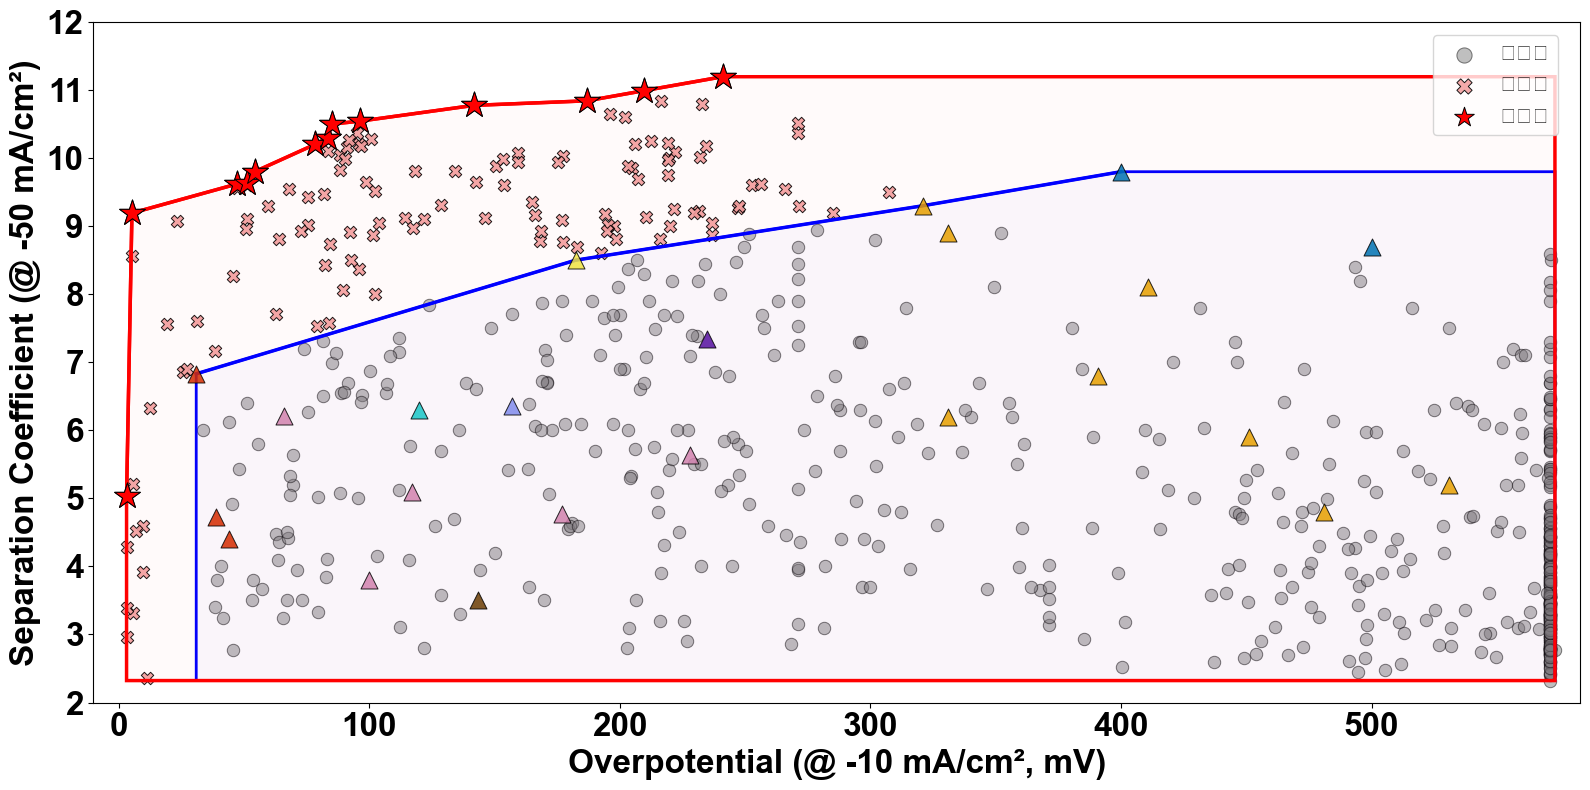

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.colors import to_rgba
from matplotlib.path import Path
import matplotlib as mpl

import re

def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    # Any literature reference -> same legend entry
    if re.match(r"^Reference\s+\d+$", lbl):
        return "Literature Report"

    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"

    return lbl


mpl.rcParams["path.simplify"] = False
# =========================
# 1) Load your Excel
# =========================
path = "../archive/dta/all_data_corrected_v2.xlsx"   # <- change if needed
raw = pd.read_excel(path, sheet_name="Sheet1")

# Make ALL column names strings so "24"/"26"... match
raw.columns = raw.columns.map(lambda c: str(c).strip())

# first row repeats headers ("Overpotential / Separation Coefficient"), drop it
df = raw.iloc[1:].copy()

def to_num(s):
    return pd.to_numeric(s, errors="coerce")

# =========================
# 2) Map each dataset to (x,y) columns
# =========================
datasets = [
    ("This work", "Unnamed: 1"),
    ("24", "Unnamed: 3"),
    ("26", "Unnamed: 5"),
    ("25", "Unnamed: 7"),
    ("27", "Unnamed: 9"),
    ("23", "Unnamed: 11"),
    ("20", "Unnamed: 13"),
    ("22", "Unnamed: 15"),
    ("Ni foam", "Unnamed: 17"),
    ("Pt sheet", "Unnamed: 19"),
]

rows = []
for x_col, y_col in datasets:
    if x_col not in df.columns or y_col not in df.columns:
        print(f"[WARN] Missing columns: {x_col} / {y_col}")
        continue
    x = to_num(df[x_col])
    y = to_num(df[y_col])
    tmp = pd.DataFrame({"label": x_col, "x": x, "y": y}).dropna()
    rows.append(tmp)

data = pd.concat(rows, ignore_index=True)
data = data[np.isfinite(data["x"]) & np.isfinite(data["y"])].copy()
data = data.reset_index(drop=True)
data["pid"] = data.index   # <-- add this

# Rename numeric refs -> "Reference 24" etc.
data["label"] = data["label"].astype(str).str.strip()
data["label"] = data["label"].apply(lambda s: f"Reference {s}" if s.isdigit() else s)

# =========================
# Apply transformation to "This work" overpotential (x-values)
# =========================
is_this = data["label"].str.strip().str.lower().eq("this work")
thisw = data[is_this].copy()

# Apply the transformations: 1. Minus, 2. Clip at 0, 3. Multiply by 1000
thisw["x"] = -(thisw["x"]) * 1000

# Replace the transformed "This work" data back into the main dataframe
data.loc[is_this, "x"] = thisw["x"]

# =========================
# 3) Pareto frontier (X lower better, Y higher better)
# =========================
def pareto_frontier_xy(pts: pd.DataFrame) -> pd.DataFrame:
    s = pts.sort_values(["x", "y"], ascending=[True, False]).reset_index(drop=True)
    best_y = -np.inf
    keep = []
    for _, r in s.iterrows():
        if r["y"] > best_y:
            keep.append(True)
            best_y = r["y"]
        else:
            keep.append(False)
    return s.loc[keep].reset_index(drop=True)

import re

def legend_name(lbl: str) -> str:
    lbl = str(lbl).strip()

    # "Reference 20" -> "[20]"
    m = re.match(r"^Reference\s+(\d+)$", lbl)
    if m:
        return f"Literature Report"

    # Case fixes
    if lbl.lower() == "ni foam":
        return "Ni Foam"
    if lbl.lower() == "pt sheet":
        return "Pt Sheet"
    if lbl.lower() == "this work":
        return "Ours"

    return lbl


is_this = data["label"].str.strip().str.lower().eq("this work")

pre  = data[~is_this].copy()   # without This work
post = data.copy()             # with This work


front_pre  = pareto_frontier_xy(pre)
front_post = pareto_frontier_xy(post)

pareto_ids = set(front_post["pid"])   # <-- add this


print("Counts:",
      "pre points =", len(pre),
      "| post points =", len(post),
      "| front_pre =", len(front_pre),
      "| front_post =", len(front_post))

# =========================
# 4) Enclosure polygon (single outline, not stepwise)
# =========================
x_max = float(data["x"].max())
y_min = float(data["y"].min())
y_max = float(data["y"].max())

x_ref = x_max * 1.00 + 1e-6
y_ref = y_min - 1e-6

def enclosure_polygon(front: pd.DataFrame, x_ref: float, y_ref: float):
    f = front.sort_values("x", ascending=True).reset_index(drop=True)
    x0, y0 = float(f.loc[0, "x"]), float(f.loc[0, "y"])
    y_last = float(f.loc[len(f) - 1, "y"])
    pts = (
        [(x0, y_ref), (x0, y0)]
        + list(map(tuple, f[["x", "y"]].iloc[1:].to_numpy()))
        + [(x_ref, y_last), (x_ref, y_ref)]
    )
    return pts

poly_pre  = enclosure_polygon(front_pre,  x_ref, y_ref)
poly_post = enclosure_polygon(front_post, x_ref, y_ref)

# =========================
# 5) Plot
# =========================
fig, ax = plt.subplots(figsize=(16, 8))

def label_sort_key(lbl: str):
    lbl = str(lbl)
    if lbl.startswith("Reference "):
        try:
            return (0, int(lbl.split()[-1]))
        except:
            return (0, 10**9)
    if lbl == "Ni foam":  return (1, 0)
    if lbl == "Pt sheet": return (1, 1)
    return (2, lbl)

other_labels = sorted(pre["label"].unique(), key=label_sort_key)

# Bright palette (no gray)
# Light / pastel palette (no green)
palette = [
    "#0072B2",  # blue
    "#E69F00",  # orange
    "#5510A0",  # purple
    "#D52B00",  # vermillion
    "#F0E442",  # yellow
    "#D182AE",  # magenta
    "#818CEC",  # magenta
    "#6B3C03",  # brown
    "#19C7C7",  # blue
]

markers = ["*"]

# If you use this option, I'd recommend Option 1 instead since it avoids green/gray better.
markers = ["^"]

style = {}
for i, lbl in enumerate(other_labels):
    style[lbl] = dict(marker=markers[i % len(markers)],
                      color=palette[i % len(palette)])

# Enclosures (low zorder so they don't cover lines/points)
c_pre  = "blue"
c_post = "red"
ax.add_patch(Polygon(poly_pre, closed=True,
                     facecolor=to_rgba(c_pre, 0.02),
                     edgecolor=to_rgba(c_pre, 1.0),
                     linewidth=2.0,
                     zorder=1))
ax.add_patch(Polygon(poly_post, closed=True,
                     facecolor=to_rgba(c_post, 0.02),
                     edgecolor=to_rgba(c_post, 1.0),
                     linewidth=2.5,
                     zorder=1))

pre_plot = pre[~pre["pid"].isin(pareto_ids)]  # <-- exclude Pareto points

lit_legend_added = False  # <-- add this before the loop

for lbl in other_labels:
    sub = pre_plot[pre_plot["label"] == lbl]
    ax.scatter(
        sub["x"], sub["y"],
        s=150, alpha=0.85,
        label="_nolegend_",
        zorder=4, **style[lbl],
        edgecolors="black", linewidths=0.7,
    )


# ---- FIXED (2): classify "This work" by being INSIDE the PRE enclosure polygon ----
thisw = data[is_this].copy()
thisw_plot = thisw[~thisw["pid"].isin(pareto_ids)]  # <-- exclude Pareto points

pre_path = Path(poly_pre)
inside_pre = pre_path.contains_points(thisw_plot[["x", "y"]].to_numpy(), radius=1e-9)

ax.scatter(thisw_plot.loc[inside_pre, "x"], thisw_plot.loc[inside_pre, "y"],
           marker="o", s=80, color="gray", alpha=0.5,edgecolors="black", linewidths=0.7,
           label="Ours", zorder=0)

ax.scatter(thisw_plot.loc[~inside_pre, "x"], thisw_plot.loc[~inside_pre, "y"],
           marker="X", s=80, color="#F3A0A0", alpha=0.9,edgecolors="black", linewidths=0.7,
           label="Ours", zorder=0)

ax.scatter(front_post["x"], front_post["y"],
           marker="*", s=380, color="red",
           edgecolors="black", linewidths=0.7, zorder=10,
           label="Ours")



# Pareto front lines
ax.plot(front_post["x"], front_post["y"], color=c_post, linewidth=2.5, zorder=2)
ax.plot(front_pre["x"], front_pre["y"], color=c_pre, linewidth=2.5, zorder=2)

# ---- (1) highlight ALL-DATA pareto-front points with red stars ----
ax.scatter(front_post["x"], front_post["y"],
           marker="*", s=380, color="red",
           edgecolors="black", linewidths=0.7, zorder=10)

ax.set_ylabel("Separation Coefficient (@ -50 mA/cm²)", fontname="Arial", fontweight="bold", fontsize = 24)
ax.set_xlabel("Overpotential (@ -10 mA/cm², mV)", fontname="Arial", fontweight="bold", fontsize = 24)
from matplotlib.ticker import MultipleLocator

ax.yaxis.set_major_locator(MultipleLocator(1))  # ticks every 1 unit
# ax.xaxis.set_major_locator(MultipleLocator(200))  # ticks every 1 unit

ax.tick_params(axis="both", which="both", labelsize=24)  # optional sizing
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontname("Arial")
    t.set_fontweight("bold")
    
ax.set_xlim(-10, x_ref + 10)
ax.set_ylim(2, 12)

# ---- Force legend: 3 entries for Ours, at upper-right ----
old_leg = ax.get_legend()
if old_leg is not None:
    old_leg.remove()

# 3 dummy handles (only for legend, not plotted)
h_inside = ax.scatter(
    [], [], marker="o", s=120,
    color="gray", alpha=0.5,
    edgecolors="black", linewidths=0.7,
    label="本工作"
)
h_outside = ax.scatter(
    [], [], marker="X", s=120,
    color="#F3A0A0", alpha=0.9,
    edgecolors="black", linewidths=0.7,
    label="本工作"
)
h_pareto = ax.scatter(
    [], [], marker="*", s=220,
    color="red", alpha=1.0,
    edgecolors="black", linewidths=0.7,
    label="本工作"
)

leg = ax.legend(
    handles=[h_inside, h_outside, h_pareto],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.99),
    frameon=True,
    prop={"family": "Arial", "weight": "bold", "size": 16},
    handletextpad=0.6,
    borderaxespad=0.3,
)

plt.tight_layout()
fig.savefig("../outputs/pareto_plot_v2——chinese.png", dpi=300)
plt.show()